# Name That LLM: какая языковая модель написала текст?
**Проект по курсу «Машинное обучение для решения научных задач». Задание 1: постановка задачи, метрика, EDA.**

Данные: Kaggle-соревнование [Name That LLM](https://www.kaggle.com/competitions/name-that-llm), файл `train.csv`, лицензия CC BY-SA 4.0.

Содержание:
1. Постановка задачи (бизнес и ML), данные
2. Метрика качества
3. Разведочный анализ (EDA)
4. Выводы для дальнейшей работы

## 1. Постановка задачи

### 1.1 Бизнес-постановка
**Клиент:** исследовательская лаборатория, которая изучает большие языковые модели (LLM).

**Проблема.** Компании выпускают много моделей, и их тексты трудно отличить на глаз. Лаборатории нужен инструмент, который по фрагменту текста называет модель-автора. Он нужен, чтобы:
- изучать стилевые «отпечатки» моделей разных компаний;
- находить признаки **дистилляции**, то есть случаев, когда одна модель обучена на ответах другой. Тогда её стиль похож на «учителя».

Автоматический детектор обрабатывает тысячи текстов быстрее и воспроизводимее ручного анализа.

**Цена ошибки.** Самая опасная ошибка — перепутать модели **разных компаний** (например, Claude и GPT): по ней можно сделать ложный вывод о копировании, а это репутационные издержки. Ошибка внутри одной компании (например, `claude-opus-5` вместо `claude-sonnet-5`) менее опасна.

**Дополнительный сценарий:** платформы и соцсети могут группировать сети ботов по модели-генератору и сообщать о нарушителе нужному провайдеру.

**Ограничение.** В данных нет текстов людей, поэтому задачу «человек или ИИ» мы не решаем. Мы считаем, что текст уже известен как сгенерированный, и определяем, *какой* моделью.

### 1.2 ML-постановка
| | |
|---|---|
| Тип задачи | **Многоклассовая классификация** текста: у каждого текста ровно один автор |
| Вход (признаки) | `text`: один абзац на английском, 36–274 слова |
| Выход (target) | `model`: одна из **18** моделей |
| Группы для валидации | `prompt_id`: номер задания. Это не признак, в тесте его нет |
| Валидация | `GroupKFold` по `prompt_id`: в тесте соревнования только новые промпты |

18 классов от 6 компаний:
- OpenAI (5): `gpt-5.5`, `gpt-5.6-luna`, `gpt-5.6-sol`, `gpt-5.6-terra`, `gpt-6-astra`
- Anthropic (5): `claude-fable-5`, `claude-opus-4-6`, `claude-opus-4-8`, `claude-opus-5`, `claude-sonnet-5`
- Google (4): `gemini-3.1-pro-preview`, `gemini-3.6-flash`, `gemini-3.7-flash`, `gemini-3.8-flash`
- ZAI (2): `glm-5.3`, `glm-5.3-flash`
- Qwen (1): `qwen3.8-max`
- Moonshot AI (1): `kimi-k3`

Метки иерархические (компания → модель). Поэтому можно решать и вспомогательную задачу на 6 классов (компания).

### 1.3 Данные
- `train.csv`: **2 699** размеченных текстов, 150 промптов × 18 моделей. Каждая модель отвечала на одни и те же задания.
- `test.csv` (скрытый, ~4 000 текстов): ответы на **другие** промпты, без меток. Предсказания проверяет Kaggle.
- По 150 текстов на класс хватает для классических моделей (TF-IDF + линейный классификатор) и для дообучения предобученных трансформеров (LoRA). Это показывают публичные решения соревнования.

## 2. Метрика качества

**Основная метрика: balanced accuracy**, то есть среднее значение recall по 18 классам:
$$\text{BA} = \frac{1}{18}\sum_{k=1}^{18} \frac{TP_k}{TP_k + FN_k}$$

**Обоснование.** Для лаборатории все модели одинаково важны. Balanced accuracy даёт каждому классу равный вес и не позволяет получить высокий скор, игнорируя редкие или трудные модели. Распределение классов в скрытом тесте неизвестно, а на трейне классы сбалансированы, поэтому BA совпадает с accuracy и легко интерпретируется: случайное угадывание даёт 1/18 ≈ 0.056. Это также официальная метрика соревнования, поэтому результаты сравнимы с лидербордом.

**Вспомогательные метрики:**
- **Balanced accuracy по компаниям** (6 классов): предсказанную модель сводим к компании. Это прямо измеряет самую дорогую ошибку из бизнес-постановки, путаницу между компаниями.
- **Macro-F1**: учитывает ещё и precision. Важно, чтобы модель не «сваливала» всё в один класс.
- **Матрица ошибок (confusion matrix)**: показывает, какие пары моделей путаются (ожидаем путаницу внутри семейств).

## 3. Разведочный анализ данных (EDA)
### 3.1 Загрузка и базовые характеристики

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# путь: Kaggle или локальная папка data/
CANDIDATES = ["/kaggle/input/competitions/name-that-llm/train.csv",
              "/kaggle/input/name-that-llm/train.csv",
              "data/train.csv"]
import glob
PATH = next((p for p in CANDIDATES if os.path.exists(p)), None) or glob.glob("/kaggle/input/**/train.csv", recursive=True)[0]
df = pd.read_csv(PATH)
print(PATH, df.shape)
df.head()

data/train.csv (2699, 4)


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [2]:
df.info()
print("\nПропуски:", df.isna().sum().to_dict())
print("Дубликаты id:", df["id"].duplicated().sum(), "| дубликаты text:", df["text"].duplicated().sum())
print("Уникальных промптов:", df["prompt_id"].nunique(), "| моделей:", df["model"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 2699 entries, 0 to 2698
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         2699 non-null   str  
 1   prompt_id  2699 non-null   str  
 2   text       2699 non-null   str  
 3   model      2699 non-null   str  
dtypes: str(4)
memory usage: 84.5 KB

Пропуски: {'id': 0, 'prompt_id': 0, 'text': 0, 'model': 0}
Дубликаты id: 0 | дубликаты text: 0
Уникальных промптов: 150 | моделей: 18


In [3]:
# компания-разработчик по имени модели
def vendor(m):
    for prefix, v in [("gpt", "OpenAI"), ("claude", "Anthropic"), ("gemini", "Google"),
                      ("glm", "ZAI"), ("qwen", "Qwen"), ("kimi", "Moonshot")]:
        if m.startswith(prefix):
            return v

df["vendor"] = df["model"].map(vendor)
VENDORS = ["OpenAI", "Anthropic", "Google", "ZAI", "Qwen", "Moonshot"]
VPAL = dict(zip(VENDORS, sns.color_palette("tab10", 6)))
MODELS = sorted(df["model"].unique(), key=lambda m: (VENDORS.index(vendor(m)), m))
MPAL = {m: VPAL[vendor(m)] for m in MODELS}

# пример: ответы разных компаний на один и тот же промпт
ex = df[df["prompt_id"] == "p081"].drop_duplicates("vendor")
for _, r in ex.iterrows():
    print(f"[{r['model']}] {r['text'][:220]}...\n")

[qwen3.8-max] When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, binding the Milky Way to ances...

[gemini-3.7-flash] When a language dies, an entire universe folds inward, erasing unmapped constellations of thought. Unique grammars of starlight, ancestral understandings of time's circular breath, and intimate dialogues with the wildern...

[gpt-5.6-terra] When a language dies, the cosmos loses more than names: it loses a particular sky. Its vanished verbs may have tracked the moon as a relative, its grammar may have folded rivers, animals, weather, and ancestors into obli...

[claude-opus-5] When the last speaker of a language falls silent, a constellation goes unnamed forever. Somewhere a people once heard the river as a verb, counted seasons by the migration of one particular bird, and held a word for the ...

[kimi-k3] When a language dies, the

**Комментарий.**
- Пропусков и дубликатов нет, данные чистые.
- Все тексты на английском, один абзац. Ответы разных моделей на один промпт начинаются почти одинаково («When a language dies…»): **тема задаётся промптом, а не моделью**. Это главный вызов задачи: нужно научиться отделять *стиль* от *содержания*.

### 3.2 Баланс классов и структура «промпт × модель»

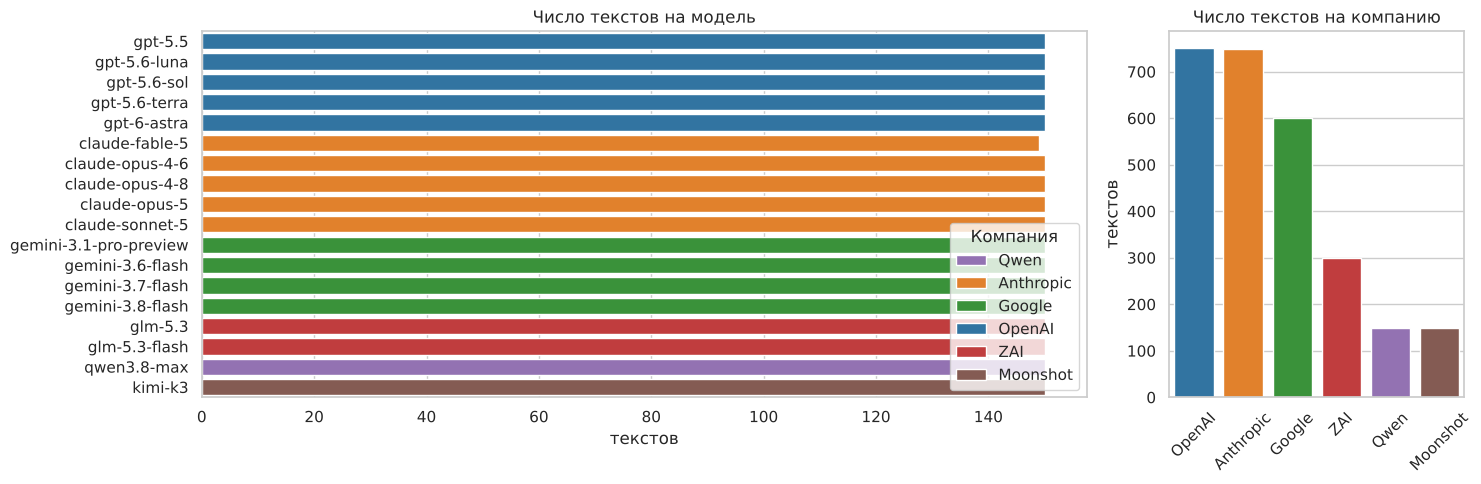

Моделей на промпт: {18: 149, 17: 1}
Промпт без ответа claude-fable-5: {'p002'}


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [3, 1]})
sns.countplot(data=df, y="model", order=MODELS, hue="vendor", palette=VPAL, dodge=False, ax=axes[0])
axes[0].set(title="Число текстов на модель", xlabel="текстов", ylabel="")
axes[0].legend(title="Компания", loc="lower right")
sns.countplot(data=df, x="vendor", order=VENDORS, hue="vendor", palette=VPAL, ax=axes[1])
axes[1].set(title="Число текстов на компанию", xlabel="", ylabel="текстов")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

per_prompt = df.groupby("prompt_id")["model"].nunique()
print("Моделей на промпт:", per_prompt.value_counts().to_dict())
missing = set(df["prompt_id"]) - set(df.loc[df["model"] == "claude-fable-5", "prompt_id"])
print("Промпт без ответа claude-fable-5:", missing)

**Комментарий.**
- По моделям классы **сбалансированы**: 150 текстов, у `claude-fable-5` 149 (нет ответа на промпт `p002`). Взвешивать классы или делать oversampling не нужно.
- По компаниям классов **нет баланса**: OpenAI и Anthropic по 750 текстов, Qwen и Moonshot по 150. Если решать задачу «компания» отдельно, нужны веса классов или balanced accuracy.
- Данные устроены как **сетка 150 × 18**: каждая модель ответила на каждый промпт. Это удобно для анализа: можно сравнивать модели «при прочих равных», на одинаковых заданиях.

### 3.3 Длина текстов

In [5]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()
df["n_sent"] = df["text"].str.count(r"[.!?](?:\s|$)").clip(lower=1)
df["words_per_sent"] = df["n_words"] / df["n_sent"]
df["chars_per_word"] = df["n_chars"] / df["n_words"]
df[["n_chars", "n_words", "n_sent", "words_per_sent", "chars_per_word"]].describe().round(1)

,n_chars,n_words,n_sent,words_per_sent,chars_per_word
count,2699.0,2699.0,2699.0,2699.0,2699.0
mean,755.3,114.7,4.8,24.1,6.6
std,377.4,58.3,2.2,10.4,0.5
min,230.0,36.0,1.0,9.2,5.3
25%,429.0,64.0,3.0,19.7,6.3
50%,670.0,101.0,5.0,22.9,6.6
75%,1027.0,157.0,6.0,26.6,7.0
max,1900.0,274.0,14.0,220.0,8.9


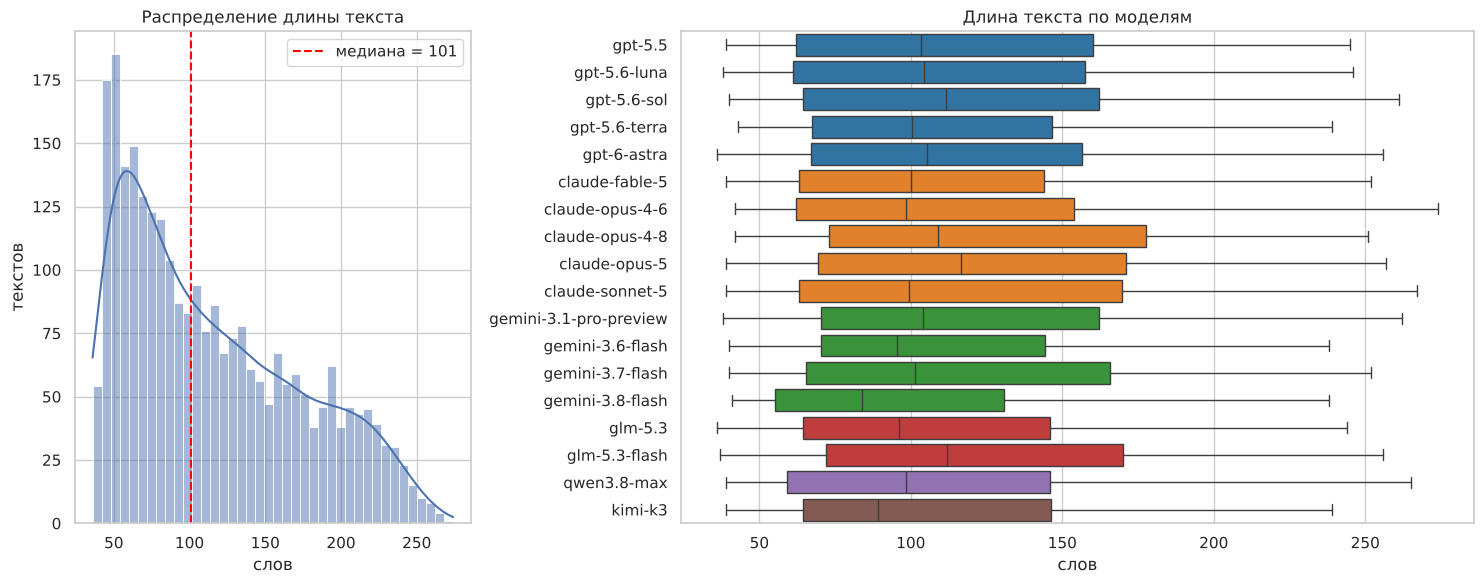

Доля дисперсии длины, объяснённая моделью: 1.0%, промптом: 5.0%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 2]})
sns.histplot(df["n_words"], bins=40, kde=True, ax=axes[0])
axes[0].axvline(df["n_words"].median(), color="red", ls="--", label=f"медиана = {df['n_words'].median():.0f}")
axes[0].set(title="Распределение длины текста", xlabel="слов", ylabel="текстов"); axes[0].legend()
sns.boxplot(data=df, y="model", x="n_words", order=MODELS, hue="model", palette=MPAL, ax=axes[1])
axes[1].set(title="Длина текста по моделям", xlabel="слов", ylabel="")
plt.tight_layout(); plt.show()

# какая доля разброса длины объясняется моделью, а какая промптом (R² однофакторного ANOVA)
total = df["n_words"].var()
r2_model = df.groupby("model")["n_words"].transform("mean").var() / total
r2_prompt = df.groupby("prompt_id")["n_words"].transform("mean").var() / total
print(f"Доля дисперсии длины, объяснённая моделью: {r2_model:.1%}, промптом: {r2_prompt:.1%}")

**Комментарий.**
- Тексты короткие: медиана ~100 слов, диапазон 36–274, распределение скошено вправо. Длинных текстов мало.
- **Длина почти не зависит от модели**: модель объясняет ~1% дисперсии длины, промпт ~5%. Ящики на boxplot почти одинаковые. Похоже, организаторы задавали целевую длину каждому ответу случайно. Вывод: **длина — слабый признак**, на неё нельзя полагаться. Зато признаки нужно нормировать на длину (считать «на 100 слов»), иначе они будут отражать длину, а не стиль.
- Короткий текст содержит мало сигнала, поэтому на коротких текстах ожидаем больше ошибок. Это стоит проверить при анализе ошибок модели.

### 3.4 Стилевые признаки: пунктуация и типографика

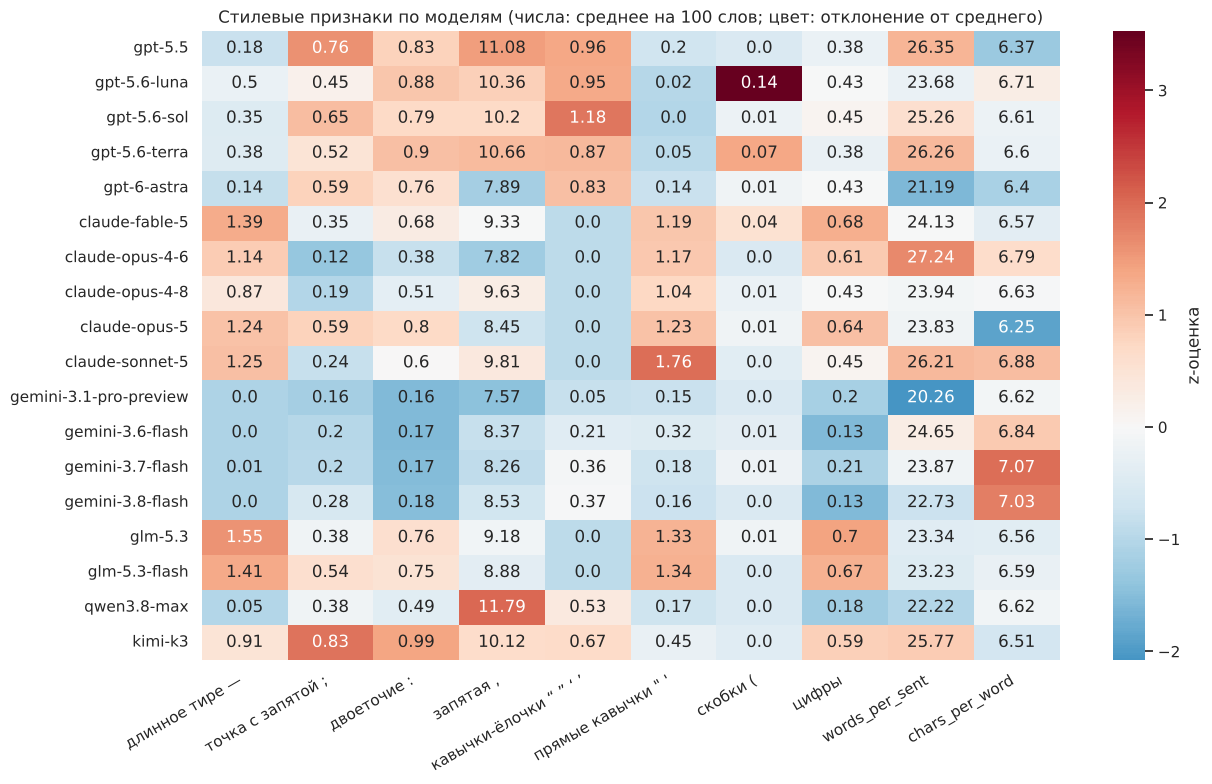

In [7]:
# признаки «на 100 слов», чтобы не зависеть от длины
STYLE = {
    "длинное тире —": "—",
    "точка с запятой ;": ";",
    "двоеточие :": ":",
    "запятая ,": ",",
    "кавычки-ёлочки “ ” ‘ ’": "[“”‘’]",
    "прямые кавычки \" '": "[\"']",
    "скобки (": r"\(",
    "цифры": r"\d",
}
for name, pat in STYLE.items():
    df[name] = df["text"].str.count(pat) / df["n_words"] * 100

style_cols = list(STYLE) + ["words_per_sent", "chars_per_word"]
means = df.groupby("model")[style_cols].mean().loc[MODELS]
z = (means - means.mean()) / means.std()   # z-оценки по столбцам

plt.figure(figsize=(13, 8))
sns.heatmap(z, cmap="RdBu_r", center=0, annot=means.round(2), fmt="", cbar_kws={"label": "z-оценка"})
plt.title("Стилевые признаки по моделям (числа: среднее на 100 слов; цвет: отклонение от среднего)")
plt.ylabel(""); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

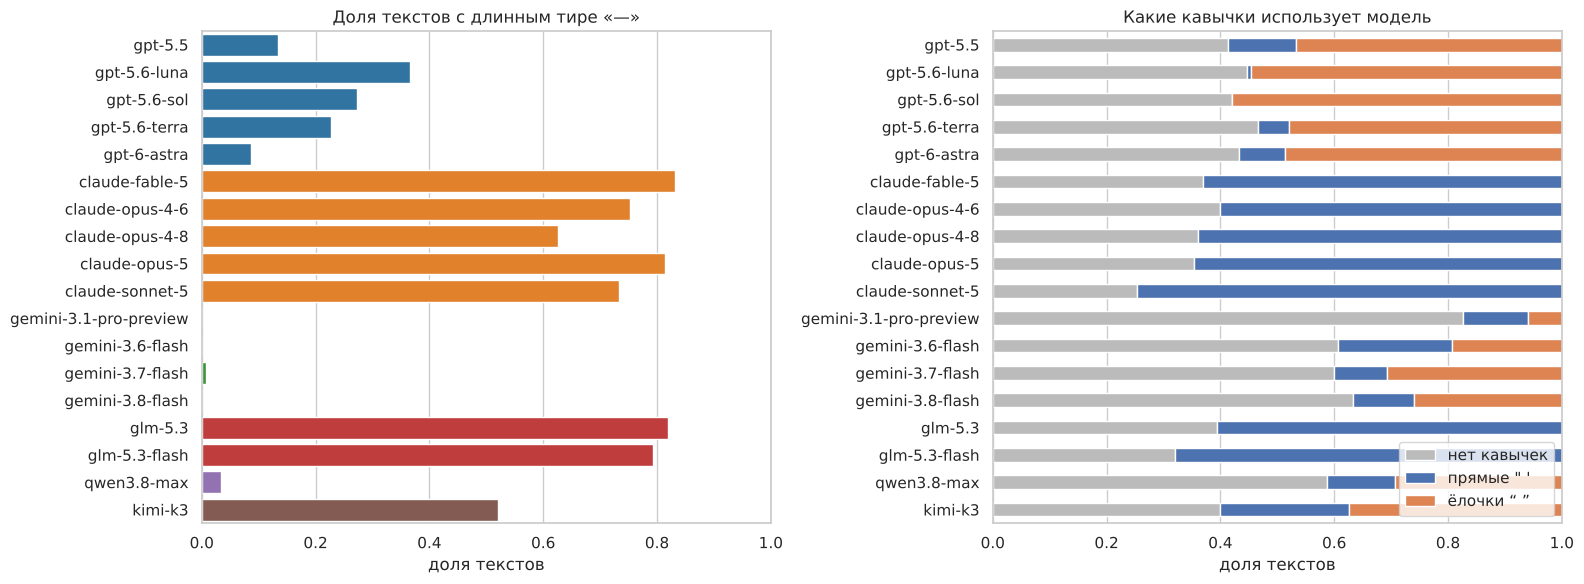

In [8]:
df["has_emdash"] = df["text"].str.contains("—")
df["quote_style"] = np.select(
    [df["text"].str.contains("[“”‘’]"), df["text"].str.contains("[\"']")],
    ["ёлочки “ ”", "прямые \" '"], "нет кавычек")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
share = df.groupby("model")["has_emdash"].mean().loc[MODELS]
sns.barplot(x=share.values, y=share.index, hue=share.index, palette=MPAL, ax=axes[0])
axes[0].set(title="Доля текстов с длинным тире «—»", xlabel="доля текстов", ylabel="", xlim=(0, 1))

ct = pd.crosstab(df["model"], df["quote_style"], normalize="index").loc[MODELS]
ct.plot(kind="barh", stacked=True, ax=axes[1], color=["#bbbbbb", "#4c72b0", "#dd8452"])
axes[1].invert_yaxis(); axes[1].set(title="Какие кавычки использует модель", xlabel="доля текстов", ylabel="")
axes[1].legend(title="", loc="lower right")
plt.tight_layout(); plt.show()

**Комментарий.** Это самый информативный блок EDA: типографика различает **компании** почти без ошибок.
- **Длинное тире «—»** есть в 63–83% текстов Claude и GLM, примерно в половине текстов Kimi, в 9–37% текстов GPT и **почти никогда** у Gemini и Qwen (0–3%).
- **Кавычки и апострофы.** GPT, Gemini и Kimi ставят типографские (`“ ” ’`), Claude и GLM — прямые (`" '`), в том числе в сокращениях (`isn't`). Это след токенизатора и пост-обработки конкретной компании.
- **GLM (ZAI) по типографике почти неотличим от Claude.** По тире, прямым кавычкам и доле цифр glm-5.3 похож на Anthropic, а не на других китайских моделей. Это как раз тот сигнал, ради которого лаборатории нужен детектор (возможная дистилляция), но проверять такую гипотезу нужно осторожно.
- **Внутри семейства** (например, 4 модели Gemini или 5 моделей Claude) пунктуация почти одинакова. Значит, такие признаки помогут определить **компанию**, а для различения версий нужны более тонкие признаки: лексика, n-граммы символов, эмбеддинги.
- **Предобработка:** нельзя нормализовать пунктуацию (заменять «—» на «-», «ёлочки» на прямые кавычки) и приводить текст к нижнему регистру без проверки: это удалит самые сильные признаки. Токенизатор тоже должен сохранять пунктуацию.

### 3.5 Лексика: характерные слова компаний

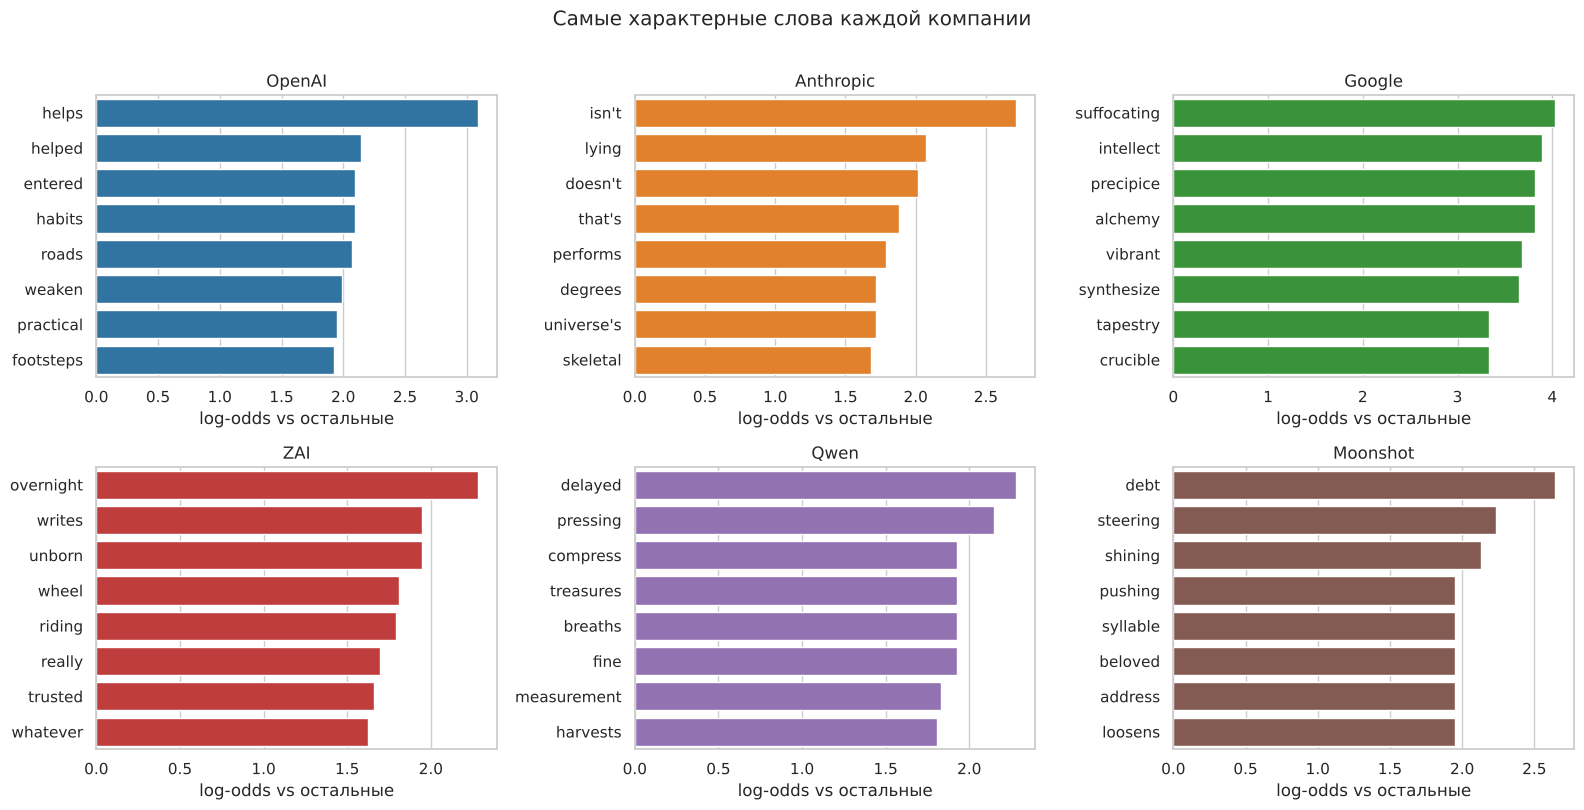

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(lowercase=True, min_df=10, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b")
Xc = cv.fit_transform(df["text"])
vocab = np.array(cv.get_feature_names_out())

# лог-отношение шансов (со сглаживанием): слово у компании vs у всех остальных
def top_words(mask, k=8, alpha=1.0):
    a = np.asarray(Xc[mask].sum(0)).ravel() + alpha
    b = np.asarray(Xc[~mask].sum(0)).ravel() + alpha
    lo = np.log(a / a.sum()) - np.log(b / b.sum())
    idx = np.argsort(lo)[::-1][:k]
    return pd.DataFrame({"word": vocab[idx], "log_odds": lo[idx]})

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, v in zip(axes.ravel(), VENDORS):
    t = top_words((df["vendor"] == v).values)
    sns.barplot(data=t, x="log_odds", y="word", color=VPAL[v], ax=ax)
    ax.set(title=v, xlabel="log-odds vs остальные", ylabel="")
plt.suptitle("Самые характерные слова каждой компании", y=1.01); plt.tight_layout(); plt.show()

**Комментарий.**
- У каждой компании есть «любимые» слова. Google тяготеет к «красивой» лексике (*tapestry, alchemy, crucible, vibrant*), Anthropic — к разговорным сокращениям (*isn't, doesn't, that's*), OpenAI — к практичным словам (*helps, practical, habits*). Их перекос (log-odds) заметен, но по отдельности слова встречаются редко, поэтому сильный сигнал даёт только **совокупность** многих слов. Это аргумент в пользу TF-IDF по словам и символьным n-граммам с линейной моделью, а не ручных правил.
- Часть характерных слов связана с темами промптов, на которые компания случайно ответила чаще. При валидации с группами по `prompt_id` такие «тематические» слова не помогут: проверим это в разделе 3.7.
- Стоп-слова удалять **не стоит**: служебные слова и связки («however», «rather», «not only») как раз отражают стиль автора. В стилометрии это классический признак.

### 3.6 Что сильнее: тема или стиль?

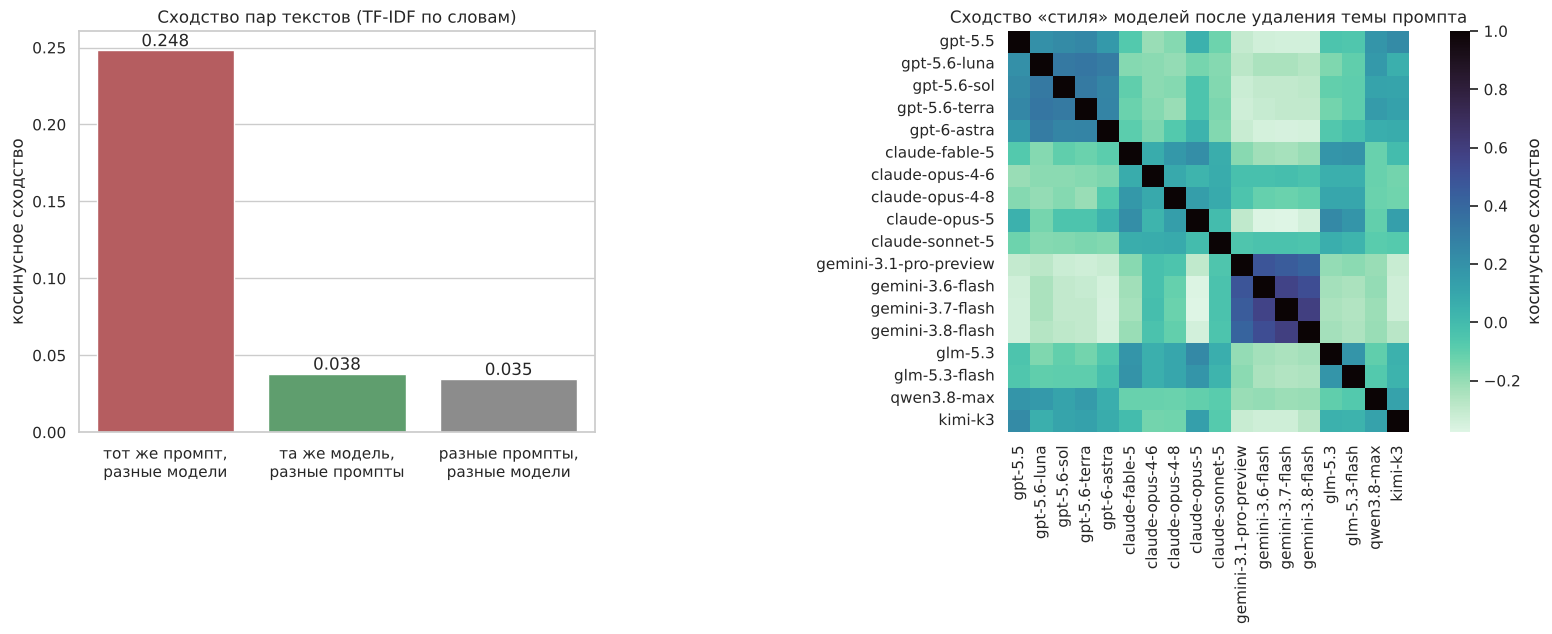

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

X = TfidfVectorizer(sublinear_tf=True, min_df=2).fit_transform(df["text"])
S = (X @ X.T).toarray()
pid, mdl = df["prompt_id"].to_numpy(), df["model"].to_numpy()
same_p, same_m = pid[:, None] == pid[None, :], mdl[:, None] == mdl[None, :]
off = ~np.eye(len(df), dtype=bool)

pairs = pd.DataFrame({
    "тип пары": ["тот же промпт,\nразные модели", "та же модель,\nразные промпты", "разные промпты,\nразные модели"],
    "косинусное сходство": [S[same_p & ~same_m & off].mean(), S[~same_p & same_m].mean(), S[~same_p & ~same_m].mean()],
})
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.6]})
sns.barplot(data=pairs, x="тип пары", y="косинусное сходство", hue="тип пары",
            palette=["#c44e52", "#55a868", "#8c8c8c"], ax=axes[0])
axes[0].set(title="Сходство пар текстов (TF-IDF по словам)", xlabel="")
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.3f")

# убираем тему: вычитаем средний вектор промпта, затем считаем «центроид стиля» каждой модели
Xd = X.toarray()
Xd = Xd - pd.DataFrame(Xd).groupby(pid).transform("mean").to_numpy()
cent = pd.DataFrame(Xd).groupby(mdl).mean().loc[MODELS]
cent = cent.div(np.linalg.norm(cent, axis=1), axis=0)
sim = pd.DataFrame(cent.to_numpy() @ cent.to_numpy().T, index=MODELS, columns=MODELS)
sns.heatmap(sim, cmap="mako_r", ax=axes[1], square=True, cbar_kws={"label": "косинусное сходство"})
axes[1].set(title="Сходство «стиля» моделей после удаления темы промпта")
plt.tight_layout(); plt.show()

**Комментарий.**
- Два ответа **разных моделей на один промпт** похожи друг на друга в ~6–7 раз сильнее, чем два ответа **одной модели на разные промпты**. Ответы одной модели на разные темы по словам похожи почти так же слабо, как совсем случайные пары. **Тема доминирует над стилем**: модель на «сырых» словах в первую очередь выучит тему.
- После вычитания «темы промпта» на тепловой карте видны блоки: модели одной компании похожи между собой. Самый плотный блок у **4 моделей Gemini**: их будет труднее всего различить. Блок GPT заметен, у Claude он слабее (версии Claude отличаются друг от друга сильнее). Значит, стиль компании есть и его можно выделить, а главная трудность — различать модели внутри семейства.
- **Идея для модели:** признаки стоит «очищать» от темы (центрировать по теме или кластеру текстов), а в тесте можно группировать тексты по теме, ведь там тоже по 18 ответов на один промпт.

### 3.7 Как валидироваться: случайное разбиение vs разбиение по промптам

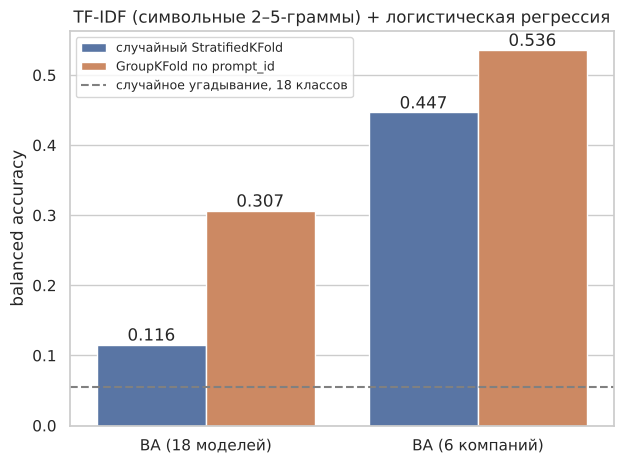

,разбиение,BA (18 моделей),BA (6 компаний)
0,случайный StratifiedKFold,0.116,0.447
1,GroupKFold по prompt_id,0.307,0.536


In [11]:
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

# простая модель только для проверки схемы валидации, не финальное решение
pipe = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2),
                     LogisticRegression(C=10, max_iter=2000))
res = []
for name, cv_, groups in [("случайный StratifiedKFold", StratifiedKFold(5, shuffle=True, random_state=0), None),
                          ("GroupKFold по prompt_id", GroupKFold(5), df["prompt_id"])]:
    pred = cross_val_predict(pipe, df["text"], df["model"], cv=cv_, groups=groups)
    res.append({"разбиение": name,
                "BA (18 моделей)": balanced_accuracy_score(df["model"], pred),
                "BA (6 компаний)": balanced_accuracy_score(df["vendor"], pd.Series(pred).map(vendor))})
res = pd.DataFrame(res)

ax = res.melt(id_vars="разбиение", var_name="метрика", value_name="balanced accuracy").pipe(
    lambda d: sns.barplot(data=d, x="метрика", y="balanced accuracy", hue="разбиение"))
ax.axhline(1/18, ls="--", color="gray", label="случайное угадывание, 18 классов")
for c in ax.containers: ax.bar_label(c, fmt="%.3f")
ax.set(title="TF-IDF (символьные 2–5-граммы) + логистическая регрессия", xlabel=""); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
res.round(3)

**Комментарий.** Результат неочевидный: **случайное разбиение даёт скор не выше, а намного ниже**.
- Почему. При случайном разбиении у текста из валидации в трейне лежат ~17 ответов **других** моделей на тот же промпт. Они очень похожи по теме (раздел 3.6), поэтому классификатор находит «соседей по теме» и отвечает их меткой, то есть ошибается. Тема работает как ловушка.
- В тесте соревнования все промпты новые. Это соответствует `GroupKFold` по `prompt_id`, поэтому **валидироваться нужно только так**. Случайное разбиение даёт искажённую оценку, и по ней можно выбрать не ту модель.
- Даже простая модель в ~5.5 раз лучше случайного угадывания (0.31 против 1/18 ≈ 0.056). Компанию она определяет с BA ≈ 0.54 при случайном уровне 1/6 ≈ 0.17. Это ещё далеко от идеала, и стилевые признаки из 3.4 должны помочь именно здесь.

## 4. Выводы для дальнейшей работы

**Данные.**
- 2 699 текстов, 18 сбалансированных классов (по 150), пропусков и дубликатов нет. По компаниям классов нет баланса (750 / 750 / 600 / 300 / 150 / 150).
- Тексты короткие (медиана ~100 слов), длина почти не зависит от модели.

**Что различает модели.**
- Типографика: длинное тире, тип кавычек, точка с запятой. Хорошо различает **компании**, слабо различает **версии** внутри семейства.
- Лексика: у компаний есть характерные слова, но сигнал распределён по многим словам.
- Тема промпта сильнее стиля, поэтому её нужно нейтрализовать.

**Предобработка.**
- **Не** приводить к нижнему регистру и **не** нормализовать пунктуацию, не удалять стоп-слова: это и есть стиль.
- Признаки нормировать на длину текста.
- Можно вычитать «тематическую» составляющую (центрирование по промпту или кластеру).

**Валидация и метрики.**
- Только `GroupKFold` по `prompt_id`.
- Основная метрика: balanced accuracy по 18 моделям. Дополнительно: BA по компаниям, macro-F1, матрица ошибок.

**Ожидаемые проблемы.**
- Путаница внутри семейств (4 Gemini, 5 GPT, 5 Claude, 2 GLM).
- Мало данных: 150 примеров на класс.
- Распределение скрытого теста может отличаться от трейна.

**План моделей.**
1. Baseline: TF-IDF (слова + символы) + линейная модель.
2. Добавить стилевые признаки.
3. Иерархическая схема «компания → модель».
4. Дообучение предобученного трансформера (LoRA).